# Fighter career statistics: exploratory plots

This notebook loads the fighter-level career statistics, visualizes correlations among all numeric predictors, and plots the distributions of the offensive predictors.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data_clean/fighter_career_stats.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data_clean/fighter_career_stats.csv")

fighter_stats = pd.read_csv(DATA_PATH)
fighter_stats.head()

,fighter,total_fights,total_fight_time,fight_quickness,win_DEC_pct,win_KO_TKO_pct,win_SUB_pct,loss_DEC_pct,loss_KO_TKO_pct,loss_SUB_pct,...,DISTANCE_absorbed_per_min,DISTANCE_opp_att_per_min,CLINCH_land_per_min,CLINCH_att_per_min,CLINCH_absorbed_per_min,CLINCH_opp_att_per_min,GROUND_land_per_min,GROUND_att_per_min,GROUND_absorbed_per_min,GROUND_opp_att_per_min
0,AJ Cunningham,2,1176,0.653333,0.0,0.0,0.0,0.500000,0.500000,0.000000,...,3.673469,5.867347,0.102041,0.153061,0.102041,0.102041,0.000000,0.000000,0.204082,0.306122
1,AJ Dobson,4,2973,0.825833,1.0,0.0,0.0,0.666667,0.333333,0.000000,...,4.036327,8.193744,0.363269,0.585267,0.423814,0.605449,0.141271,0.262361,1.150353,1.614531
2,AJ Fletcher,4,2769,0.769167,0.0,0.0,1.0,0.666667,0.000000,0.333333,...,3.250271,6.717226,0.260022,0.433369,0.650054,0.888407,0.216685,0.390033,0.866739,1.170098
3,Aalon Cruz,2,185,0.102778,0.0,0.0,0.0,0.000000,1.000000,0.000000,...,2.918919,4.540541,0.000000,0.000000,2.270270,2.594595,0.000000,0.000000,15.891892,22.702703
4,Aaron Brink,1,55,0.061111,0.0,0.0,0.0,0.000000,0.000000,1.000000,...,2.181818,2.181818,0.000000,2.181818,0.000000,2.181818,0.000000,0.000000,0.000000,0.000000


In [ ]:
# Identify missing values before performing exploratory analysis.
missing_mask = fighter_stats.isna()
missing_summary = (
    missing_mask.sum()
    .loc[lambda counts: counts.gt(0)]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)
missing_summary["missing_pct"] = (
    100 * missing_summary["missing_count"] / len(fighter_stats)
)

missing_observations = fighter_stats.loc[missing_mask.any(axis=1)].copy()
missing_observations["missing_columns"] = missing_mask.loc[
    missing_observations.index
].apply(lambda row: ", ".join(row.index[row]), axis=1)

print(f"Observations with at least one missing value: {len(missing_observations):,}")
display(missing_summary)
display(missing_observations[["fighter", "missing_columns"]])

## Correlations among continuous predictors

The fighter name is non-numeric and is excluded automatically. The upper triangle is hidden because the correlation matrix is symmetric.

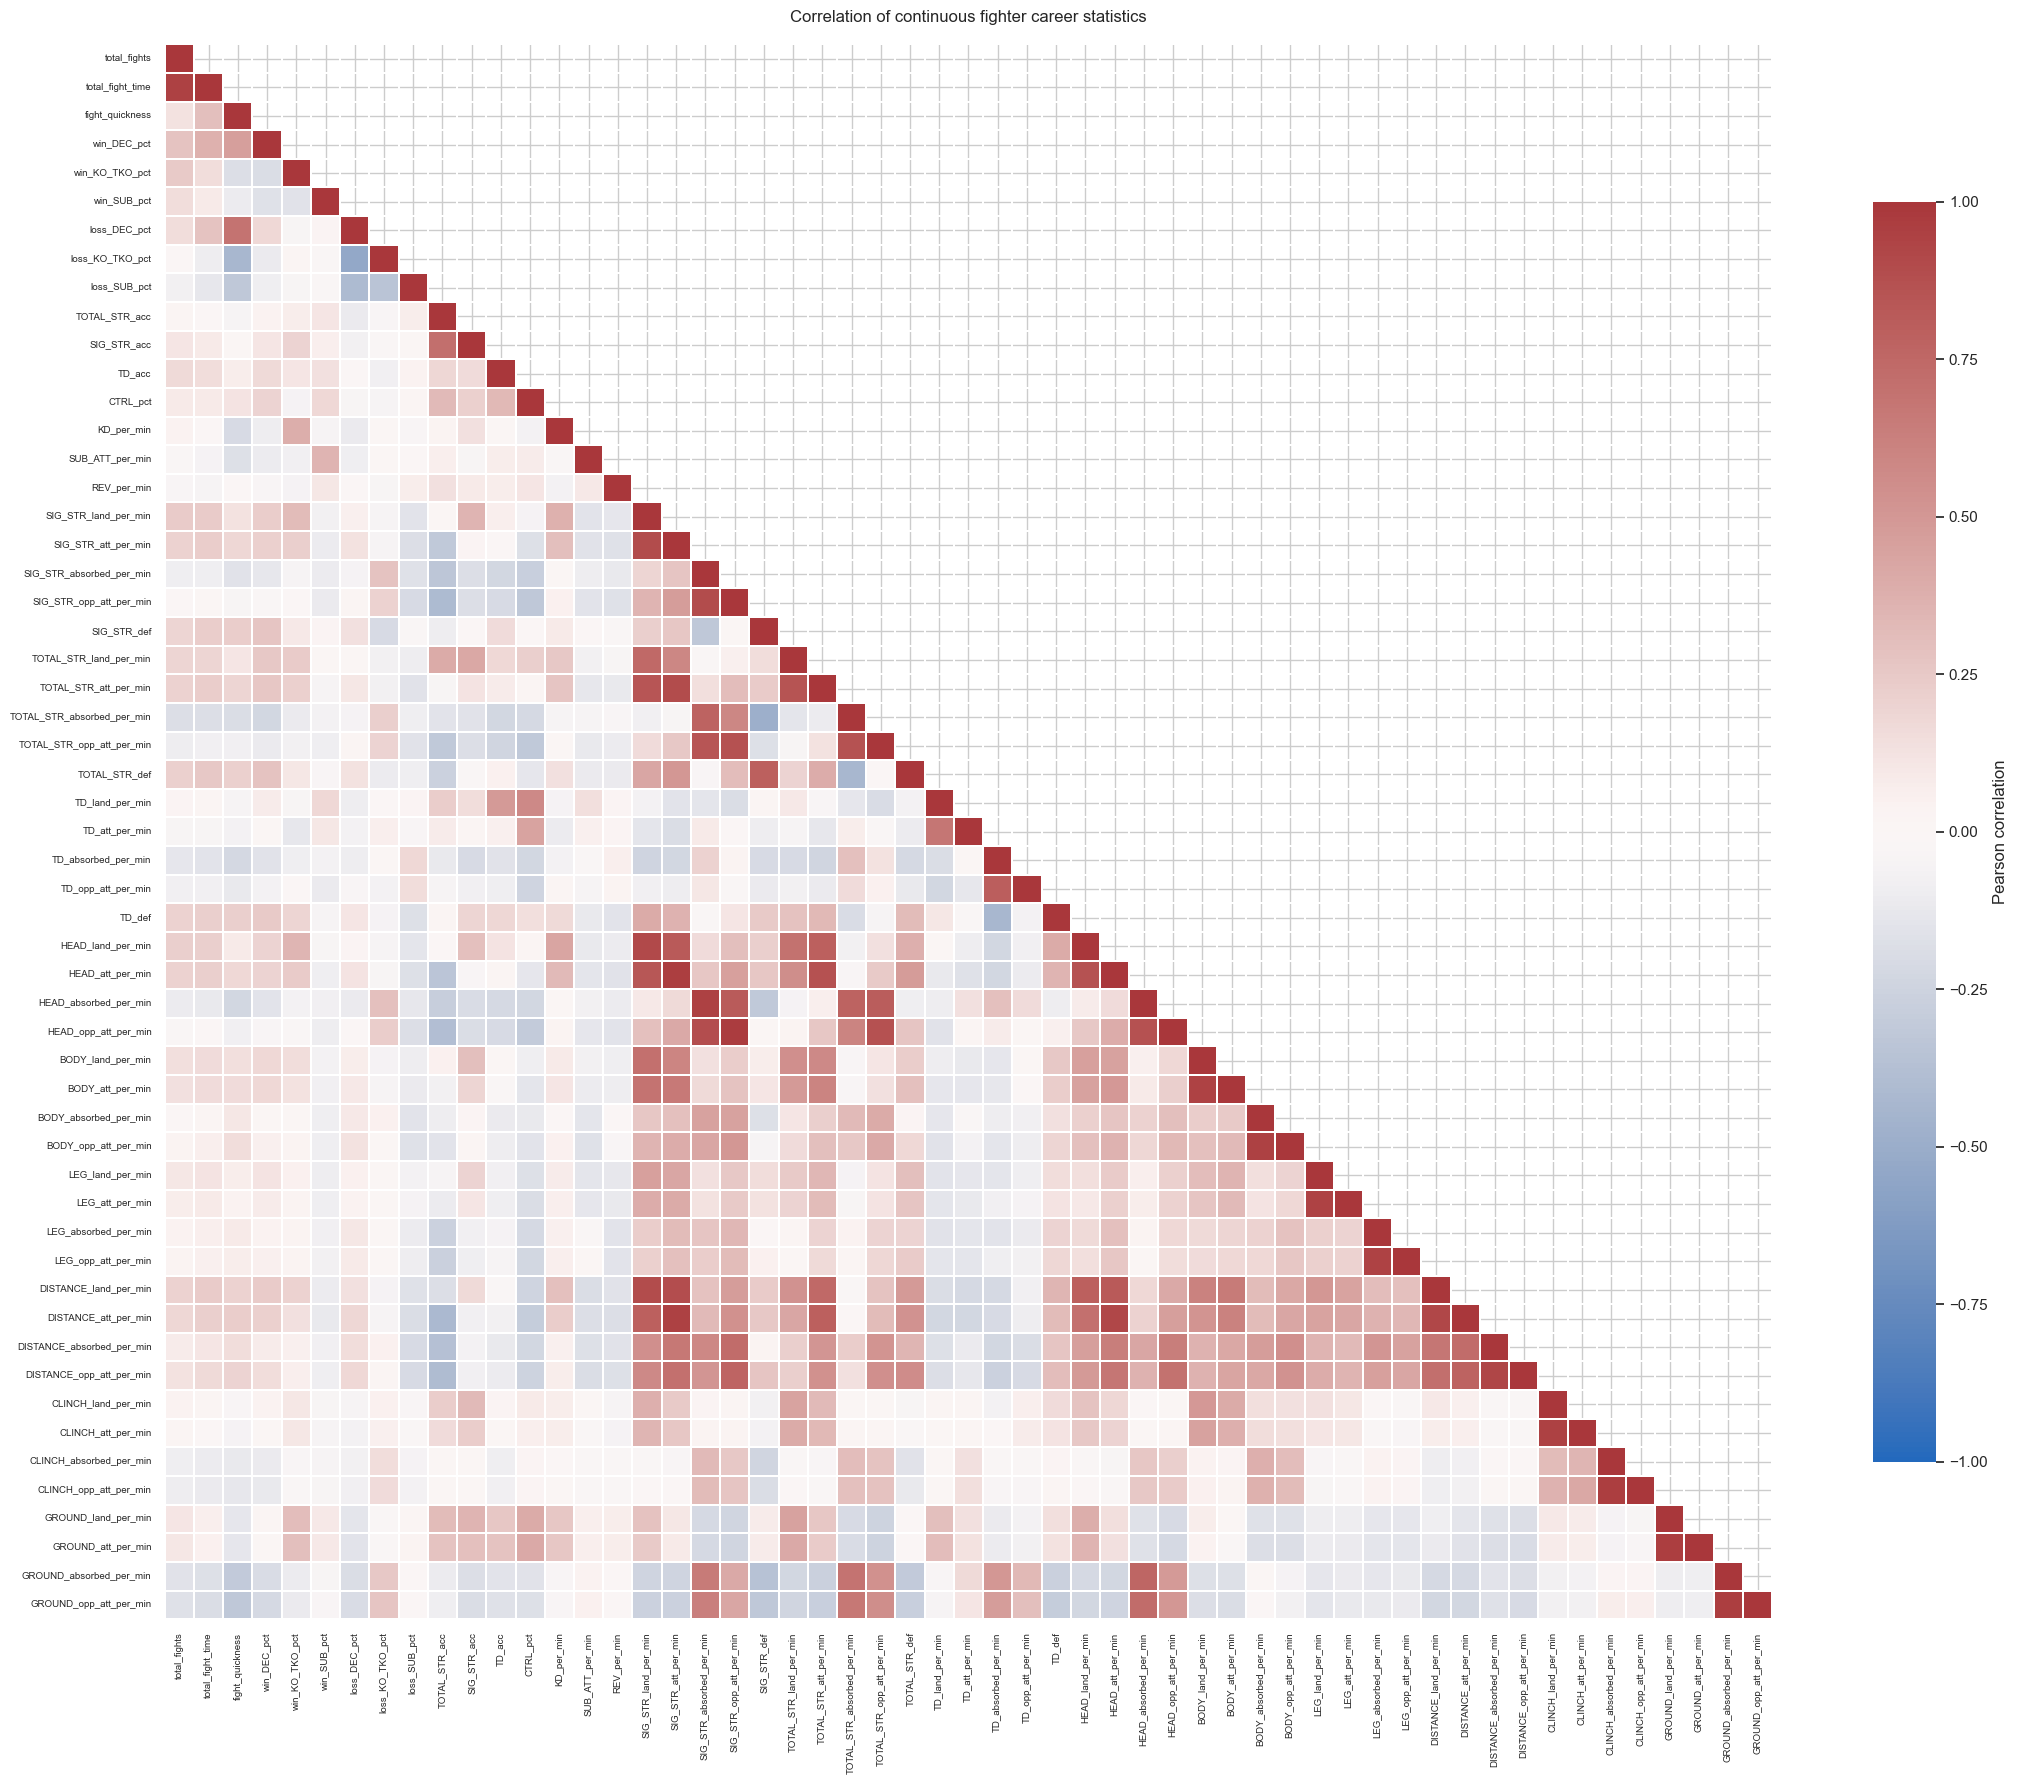

In [12]:
continuous_stats = (
    fighter_stats.select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="all")
)
correlations = continuous_stats.corr()
upper_triangle = np.triu(np.ones_like(correlations, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    correlations,
    mask=upper_triangle,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.25,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Correlation of continuous fighter career statistics", pad=16)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## Histogram and density distributions of offensive predictors

Offensive predictors include accuracy and control metrics; knockdowns, submission attempts, and reversals per minute; and each fighter's own landed and attempted rates. Opponent-attempt, absorbed, defense, and outcome variables are not included. Each subplot combines a density-scaled histogram with a KDE curve and has its own x-axis so variables with different scales remain readable.

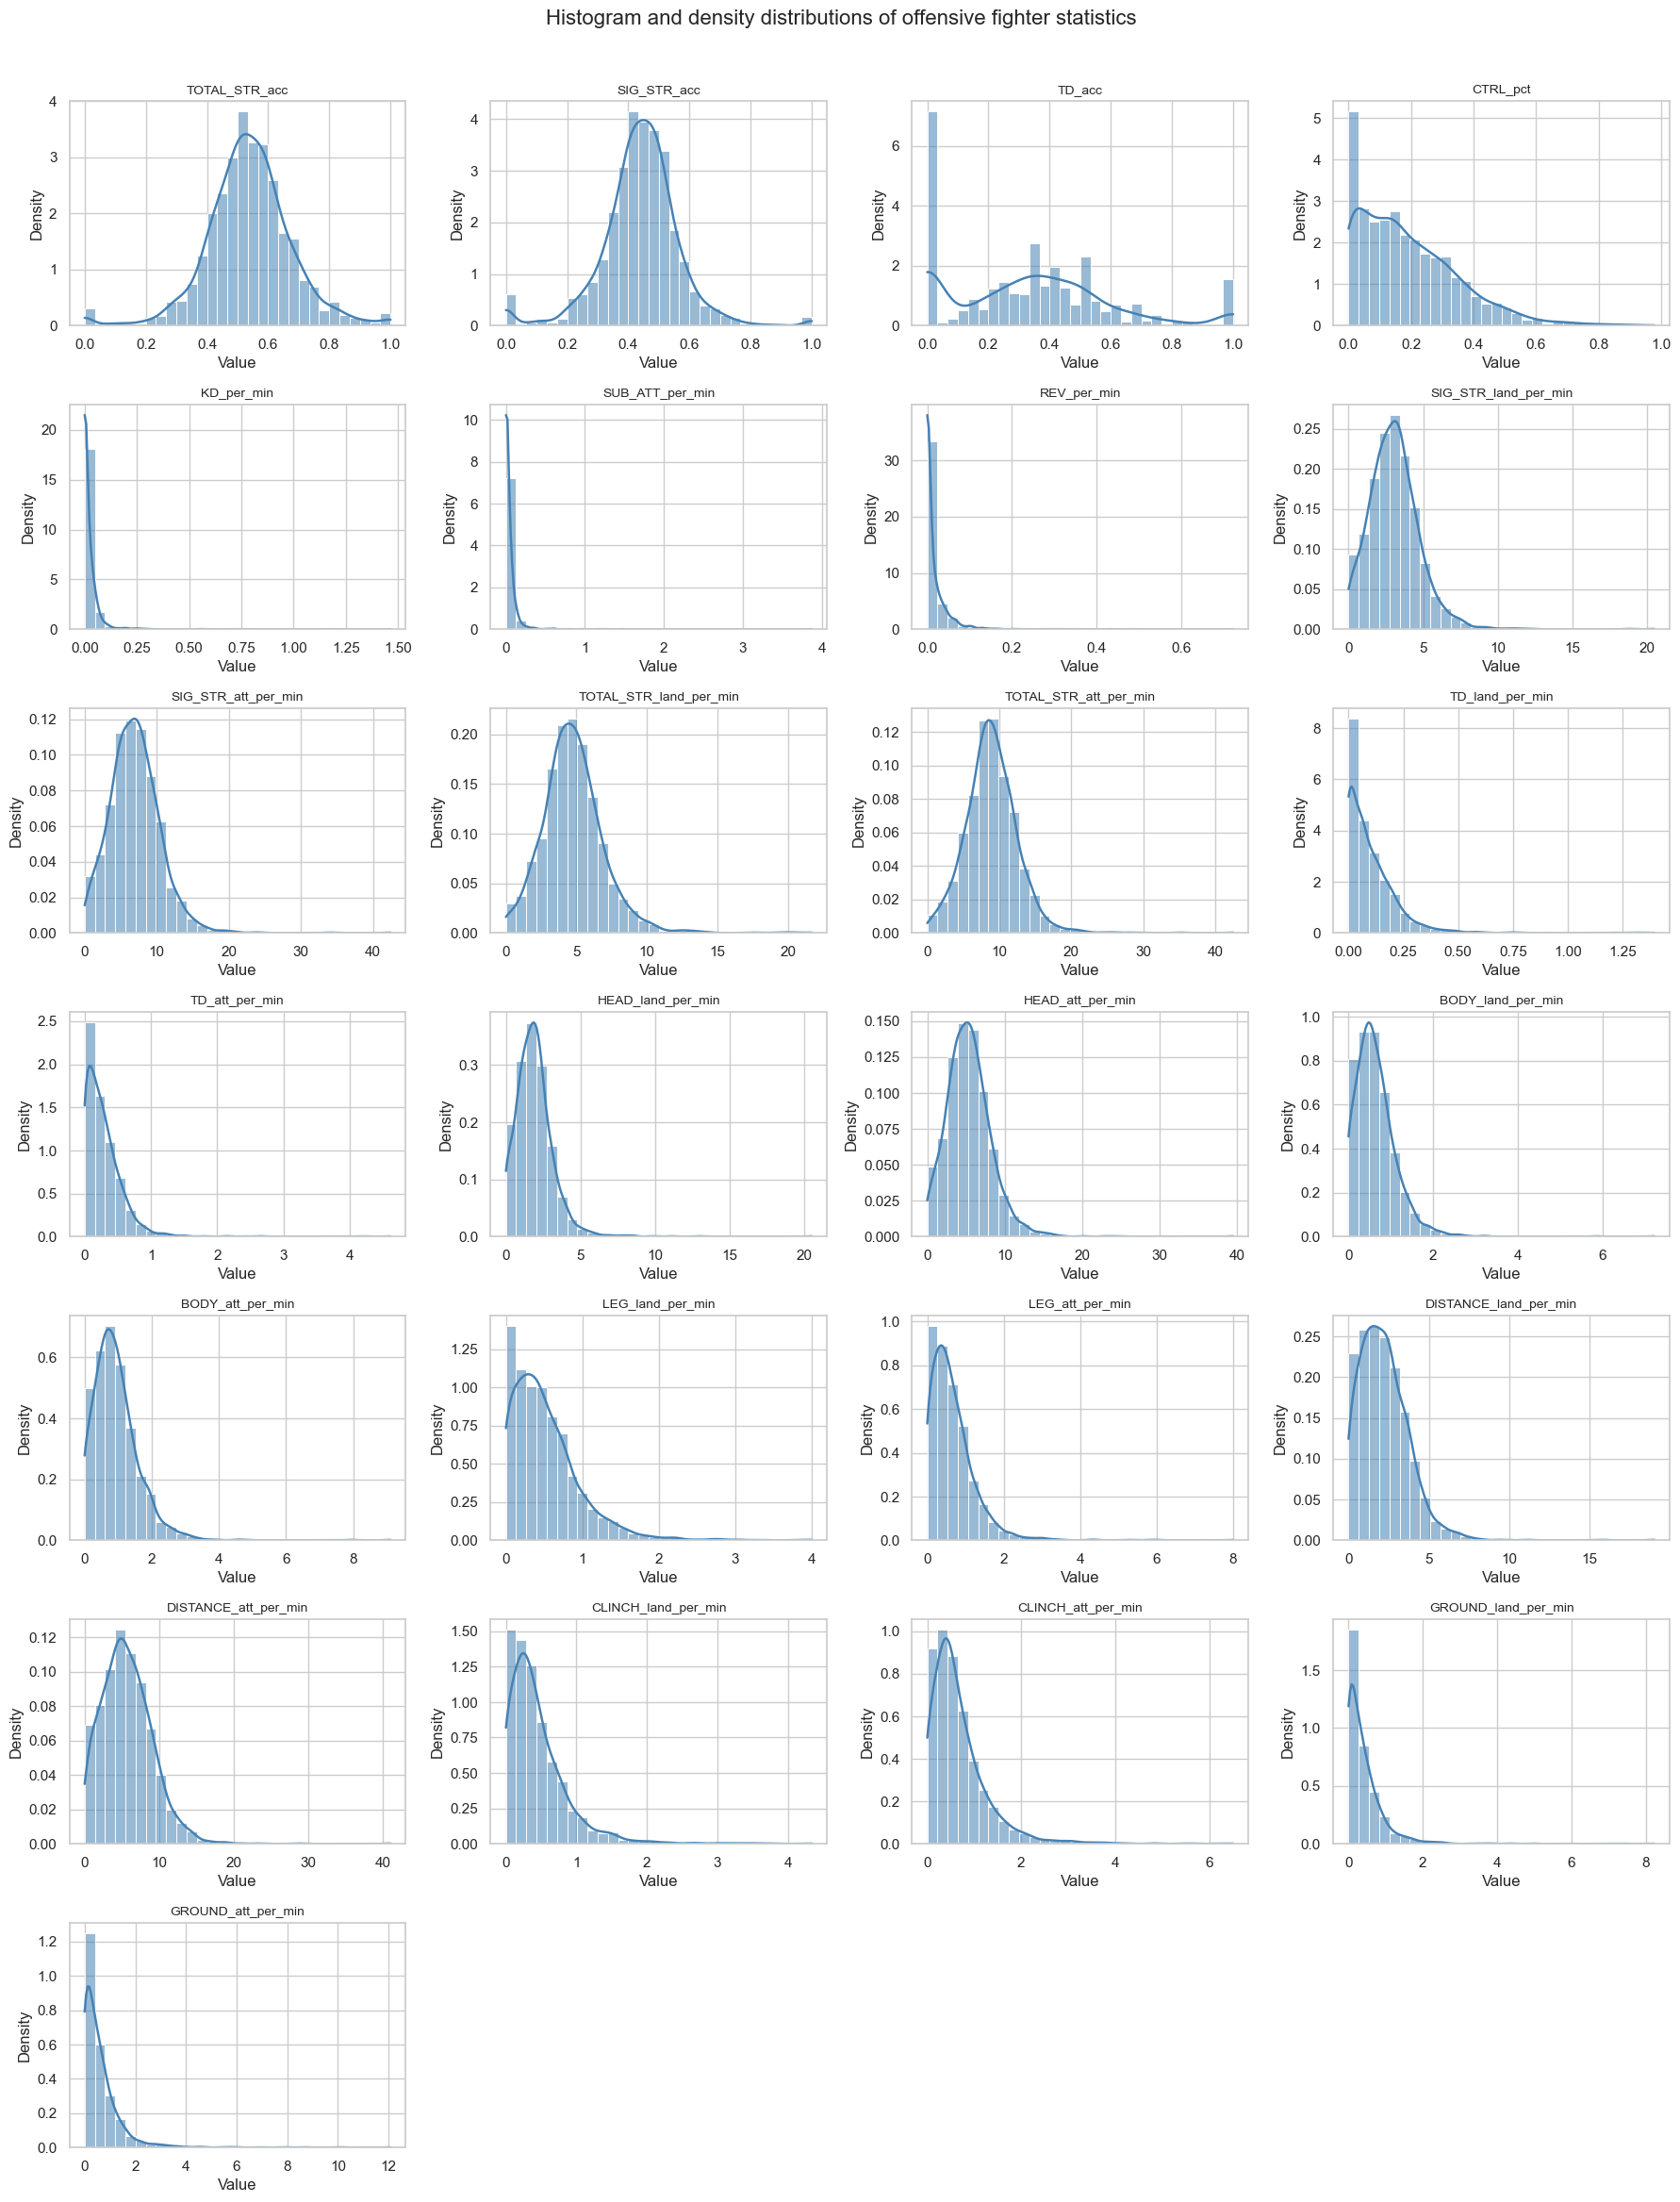

In [13]:
offensive_summary_columns = {
    "TOTAL_STR_acc",
    "SIG_STR_acc",
    "TD_acc",
    "CTRL_pct",
    "KD_per_min",
    "SUB_ATT_per_min",
    "REV_per_min",
}

offensive_columns = [
    column
    for column in continuous_stats.columns
    if (
        column in offensive_summary_columns
        or column.endswith(("_land_per_min", "_att_per_min"))
    )
    and "_opp_" not in column
    and "_absorbed_" not in column
]

n_columns = 4
n_rows = int(np.ceil(len(offensive_columns) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(18, 3.3 * n_rows))
axes = np.asarray(axes).ravel()

for ax, column in zip(axes, offensive_columns):
    values = continuous_stats[column].dropna()
    if values.nunique() > 1:
        sns.histplot(
            values,
            bins=30,
            stat="density",
            kde=True,
            color="steelblue",
            alpha=0.55,
            line_kws={"color": "navy", "linewidth": 1.8},
            ax=ax,
        )
    elif not values.empty:
        ax.axvline(values.iloc[0], linewidth=2)
    ax.set_title(column, fontsize=10)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

for ax in axes[len(offensive_columns):]:
    ax.remove()

fig.suptitle("Histogram and density distributions of offensive fighter statistics", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

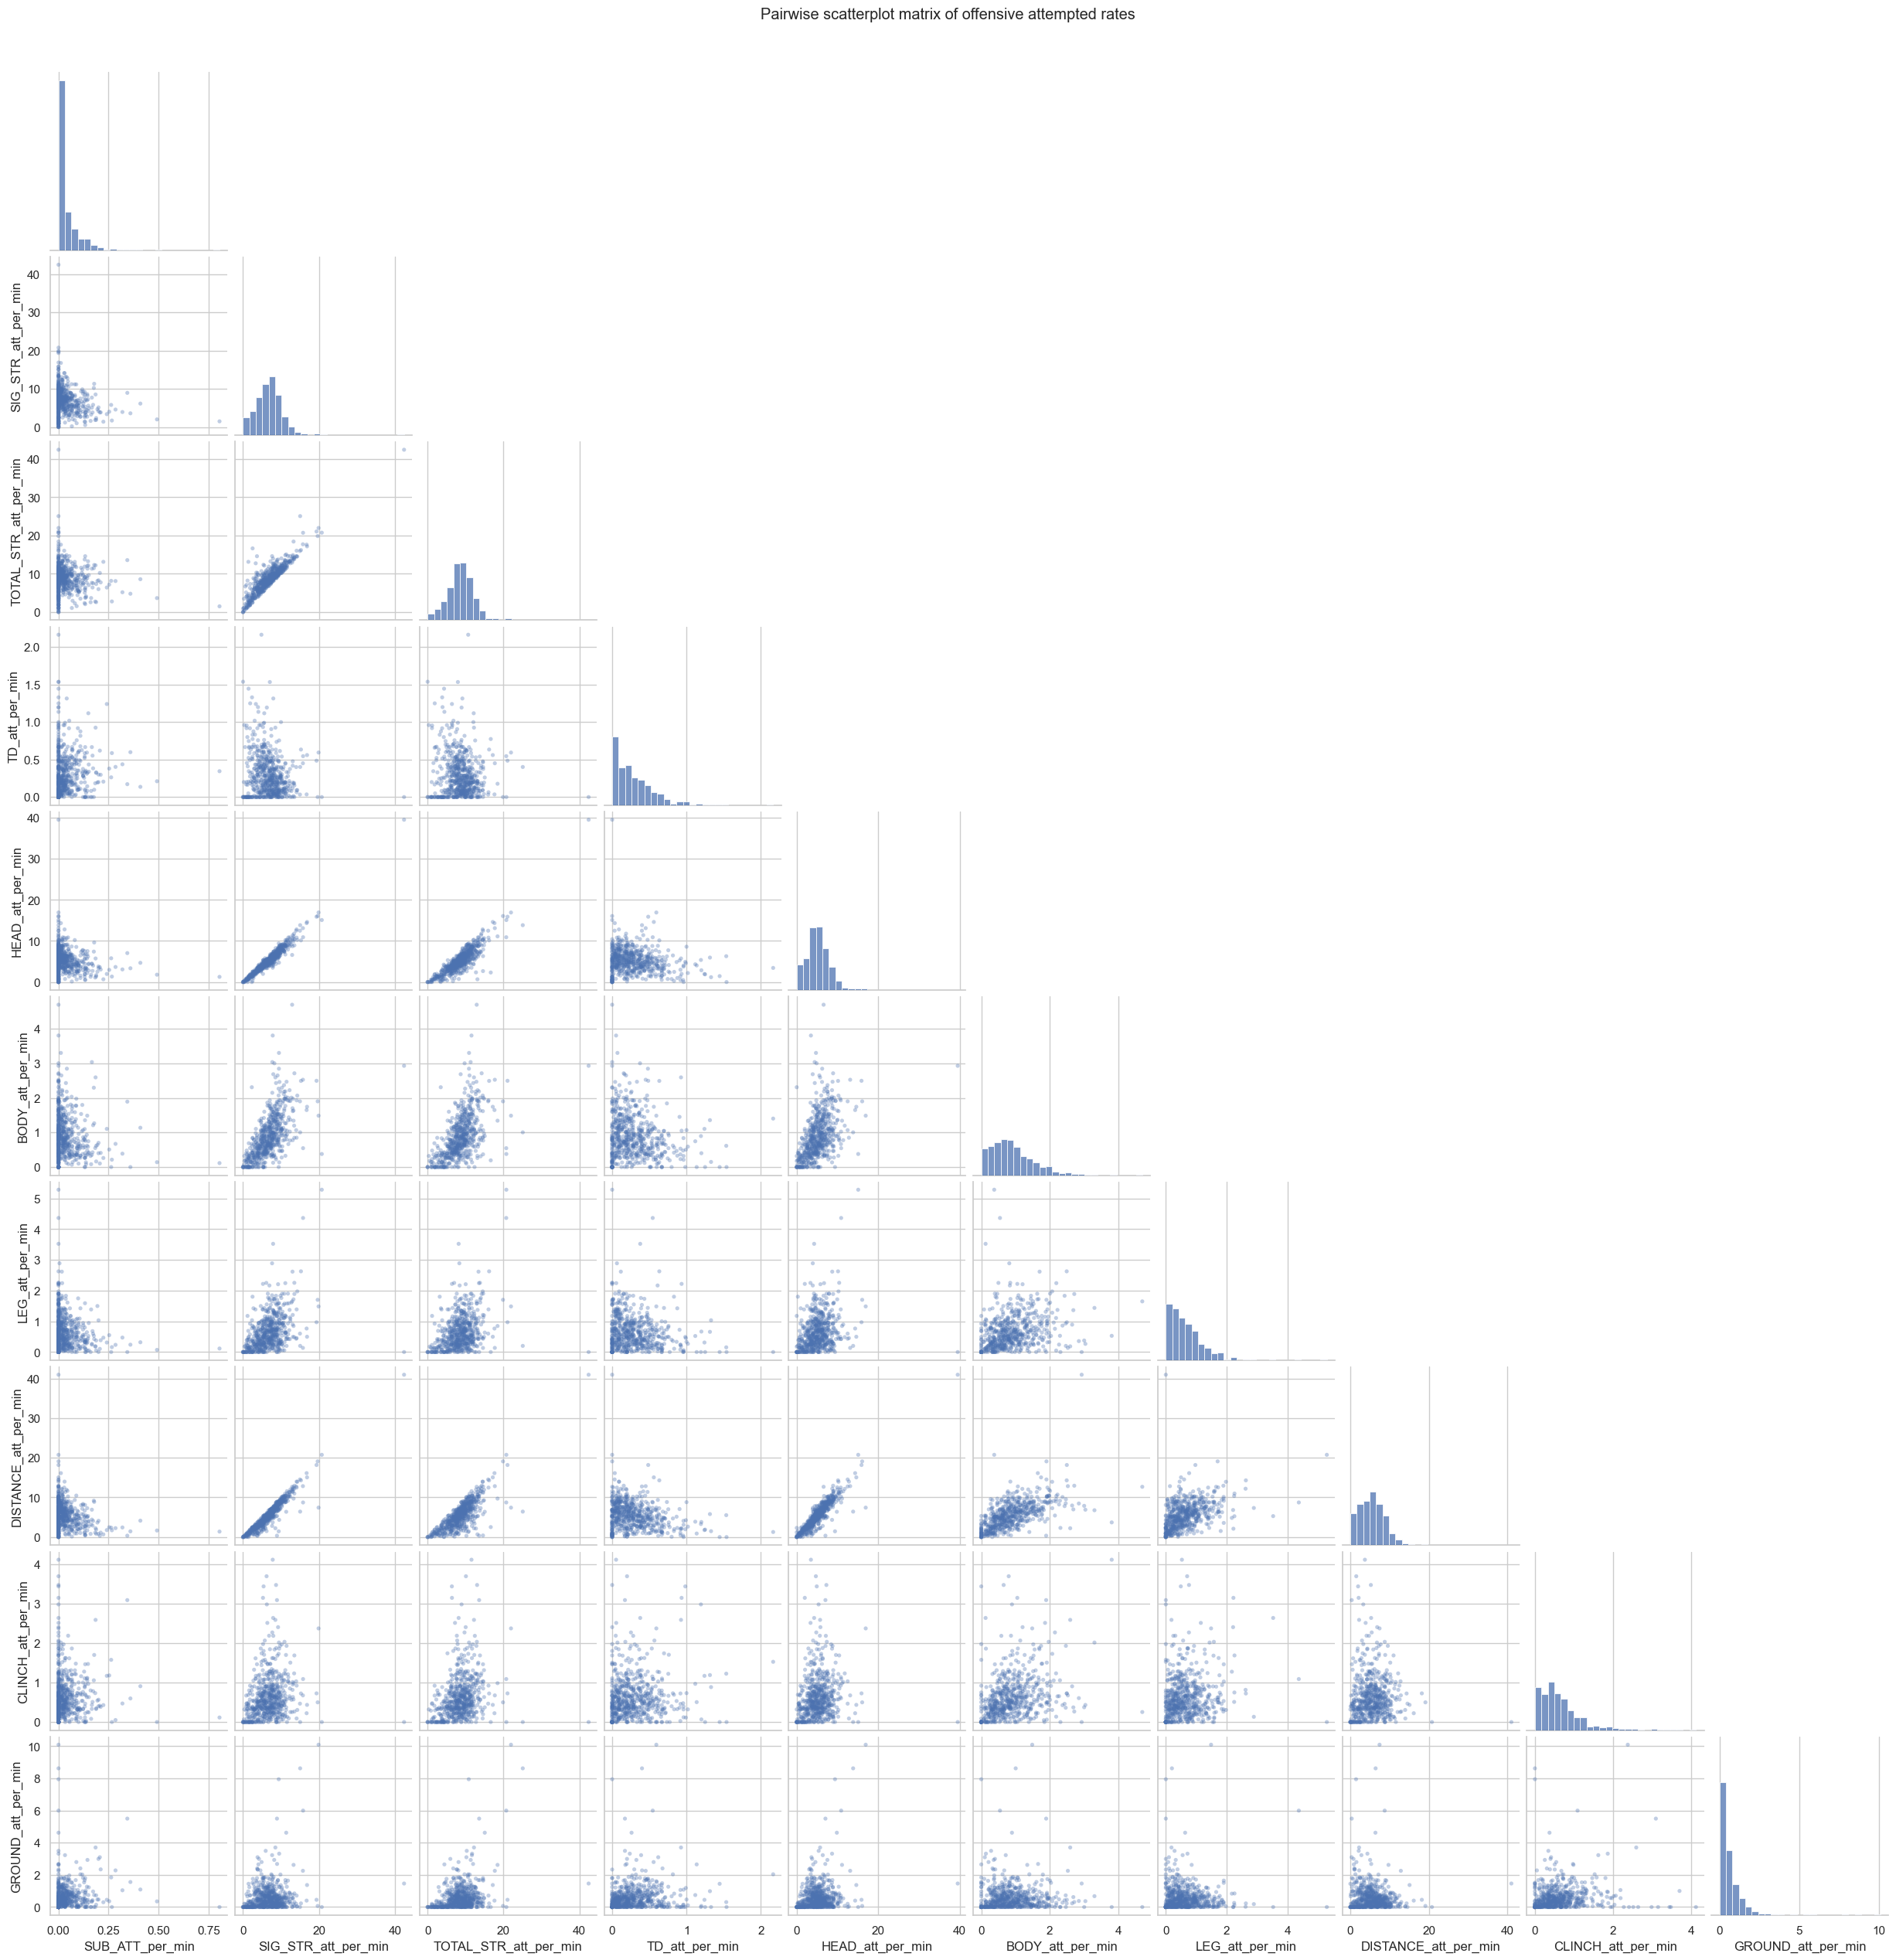

In [15]:
# Limit the matrix to the attempted-rate metrics in the offensive histogram grid.
attempt_columns = [
    column for column in offensive_columns if column.lower().endswith("_att_per_min")
]

attempt_stats = continuous_stats[attempt_columns].dropna()
attempt_stats = attempt_stats.sample(
    n=min(600, len(attempt_stats)), random_state=42
)

attempt_grid = sns.pairplot(
    attempt_stats,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"},
    diag_kws={"bins": 25},
)
attempt_grid.figure.suptitle("Pairwise scatterplot matrix of offensive attempted rates", y=1.02)
plt.show()

## Exploratory analysis: fighters with at least three recorded fights

The following plots repeat the exploratory analysis after excluding fighters with fewer than three recorded fights.

In [16]:
MIN_TOTAL_FIGHTS = 3

filtered_fighter_stats = fighter_stats.loc[
    fighter_stats["total_fights"].ge(MIN_TOTAL_FIGHTS)
].copy()
filtered_continuous_stats = (
    filtered_fighter_stats.select_dtypes(include="number")
    .replace([np.inf, -np.inf], np.nan)
    .dropna(axis=1, how="all")
)

print(
    f"Retained {len(filtered_fighter_stats):,} of {len(fighter_stats):,} fighters "
    f"with total_fights >= {MIN_TOTAL_FIGHTS}."
)

Retained 1,858 of 2,683 fighters with total_fights >= 3.


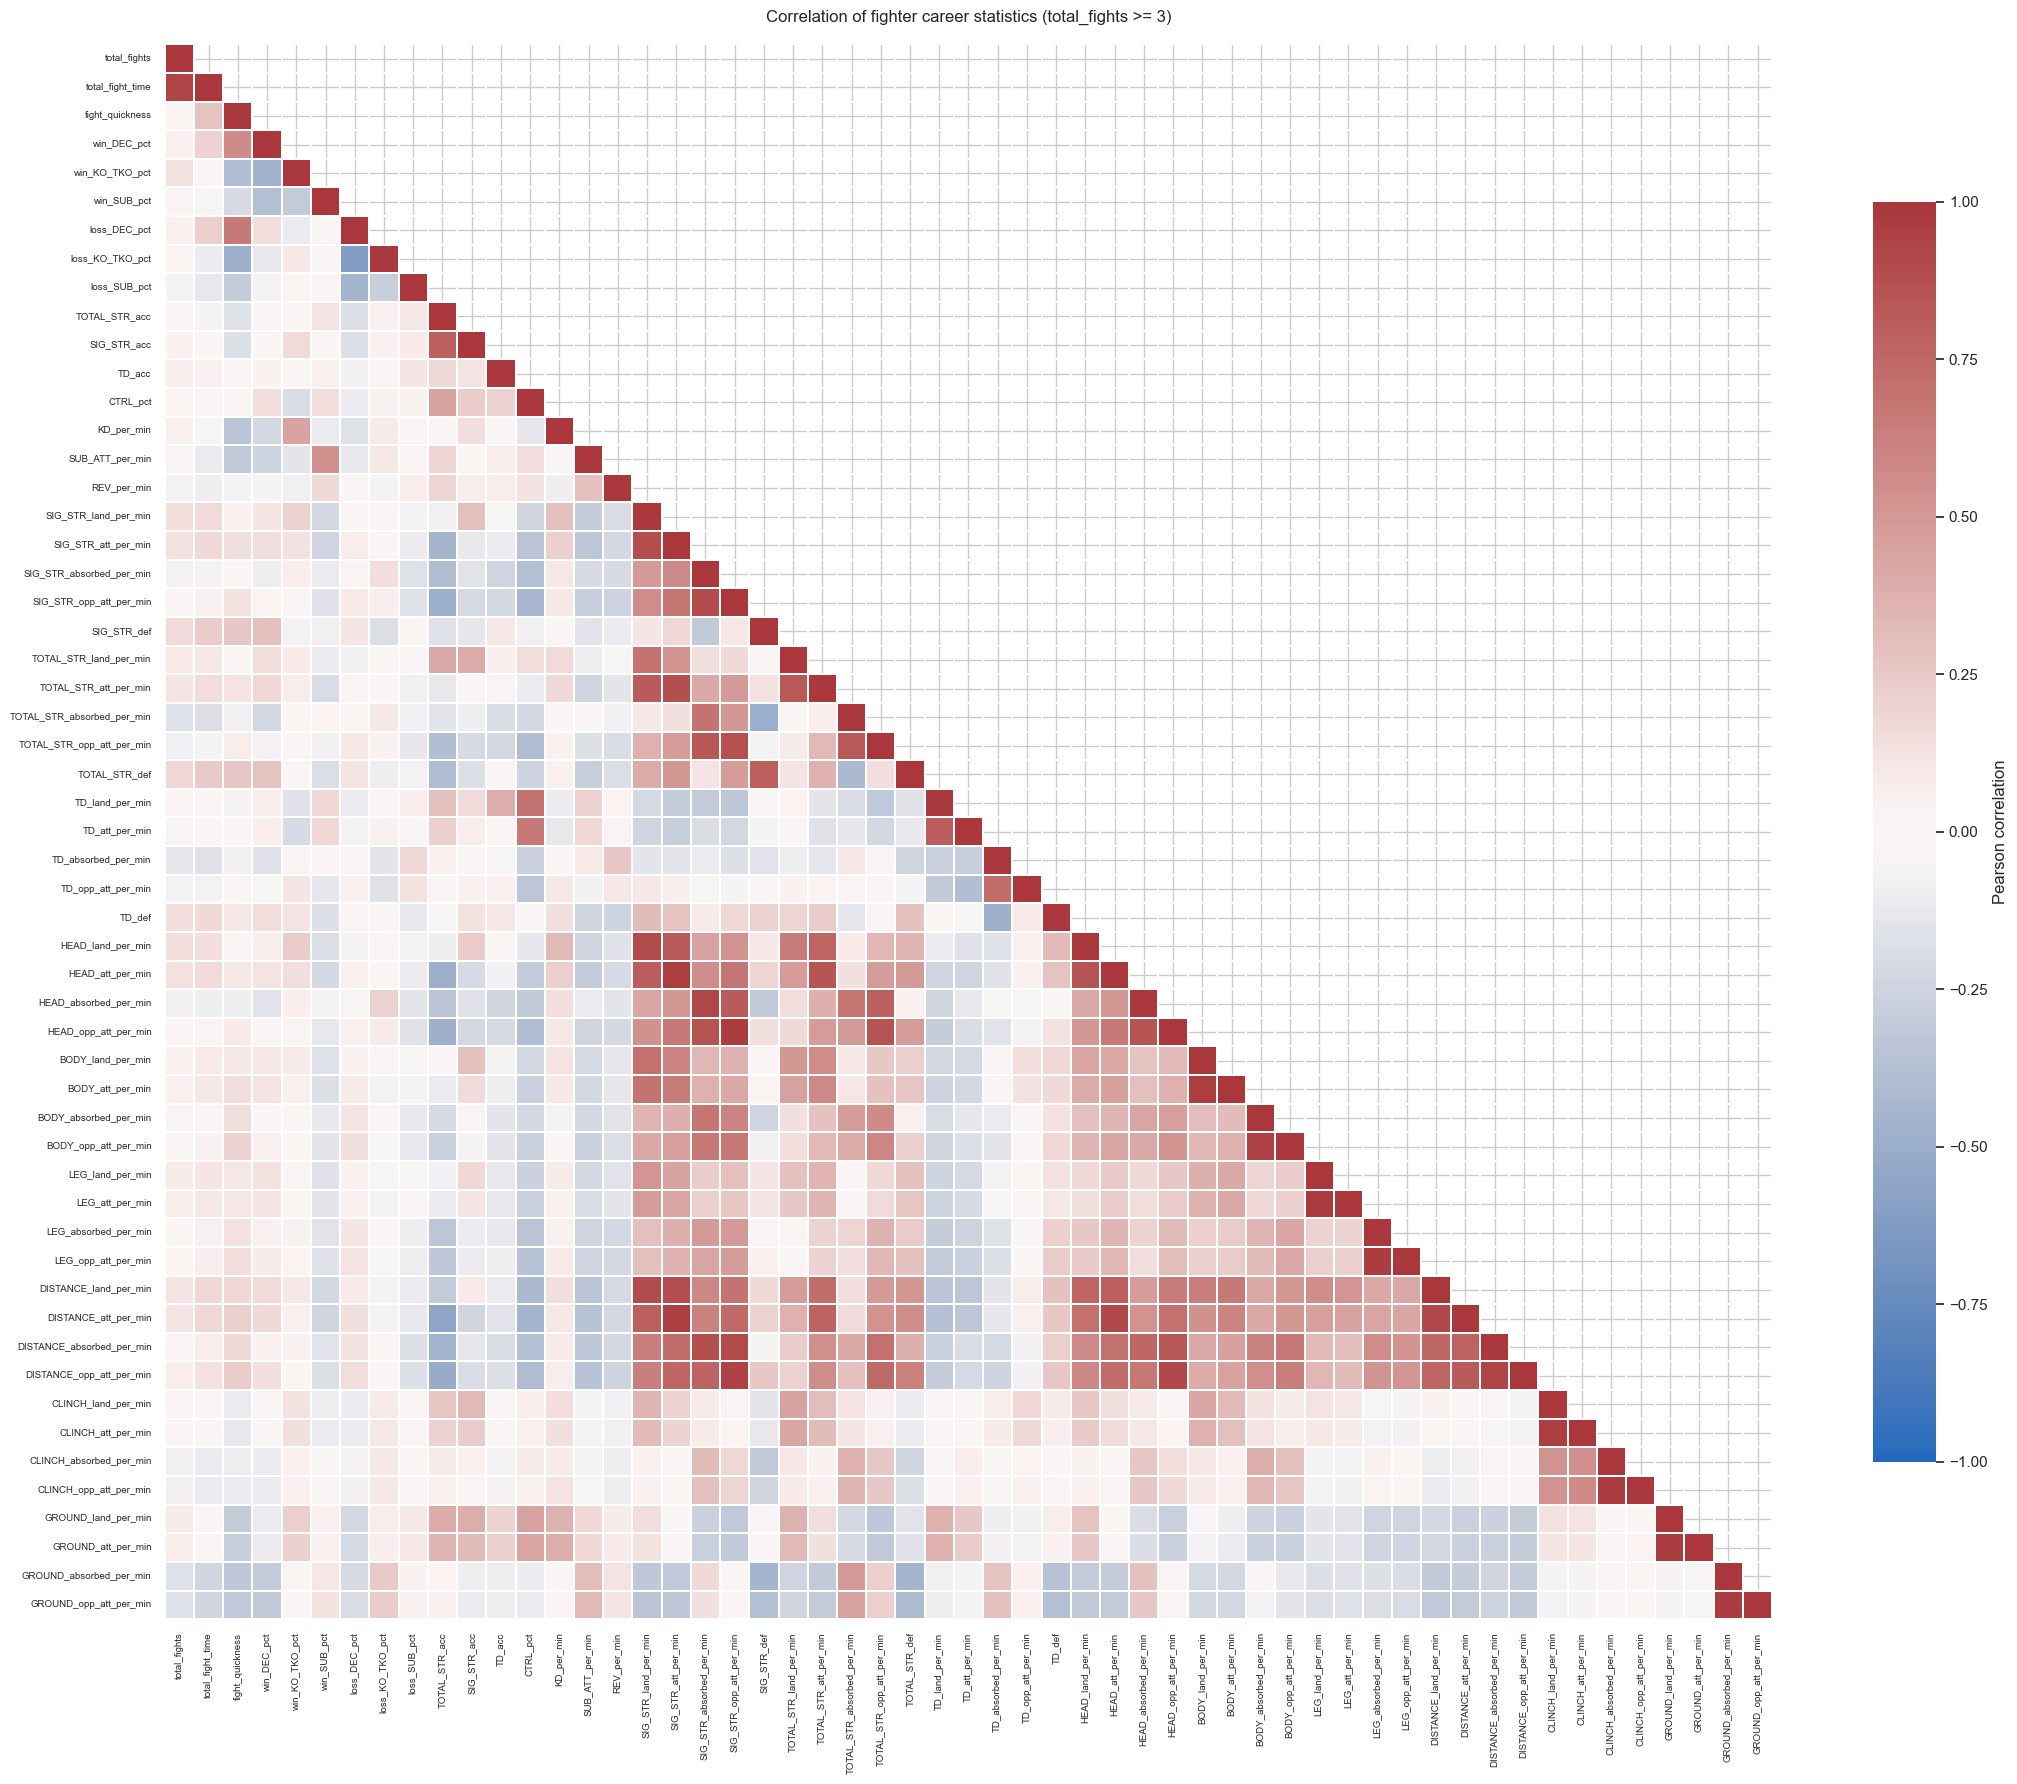

In [17]:
filtered_correlations = filtered_continuous_stats.corr()
filtered_upper_triangle = np.triu(
    np.ones_like(filtered_correlations, dtype=bool), k=1
)

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    filtered_correlations,
    mask=filtered_upper_triangle,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.25,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Correlation of fighter career statistics (total_fights >= 3)", pad=16)
ax.tick_params(axis="x", labelsize=7)
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

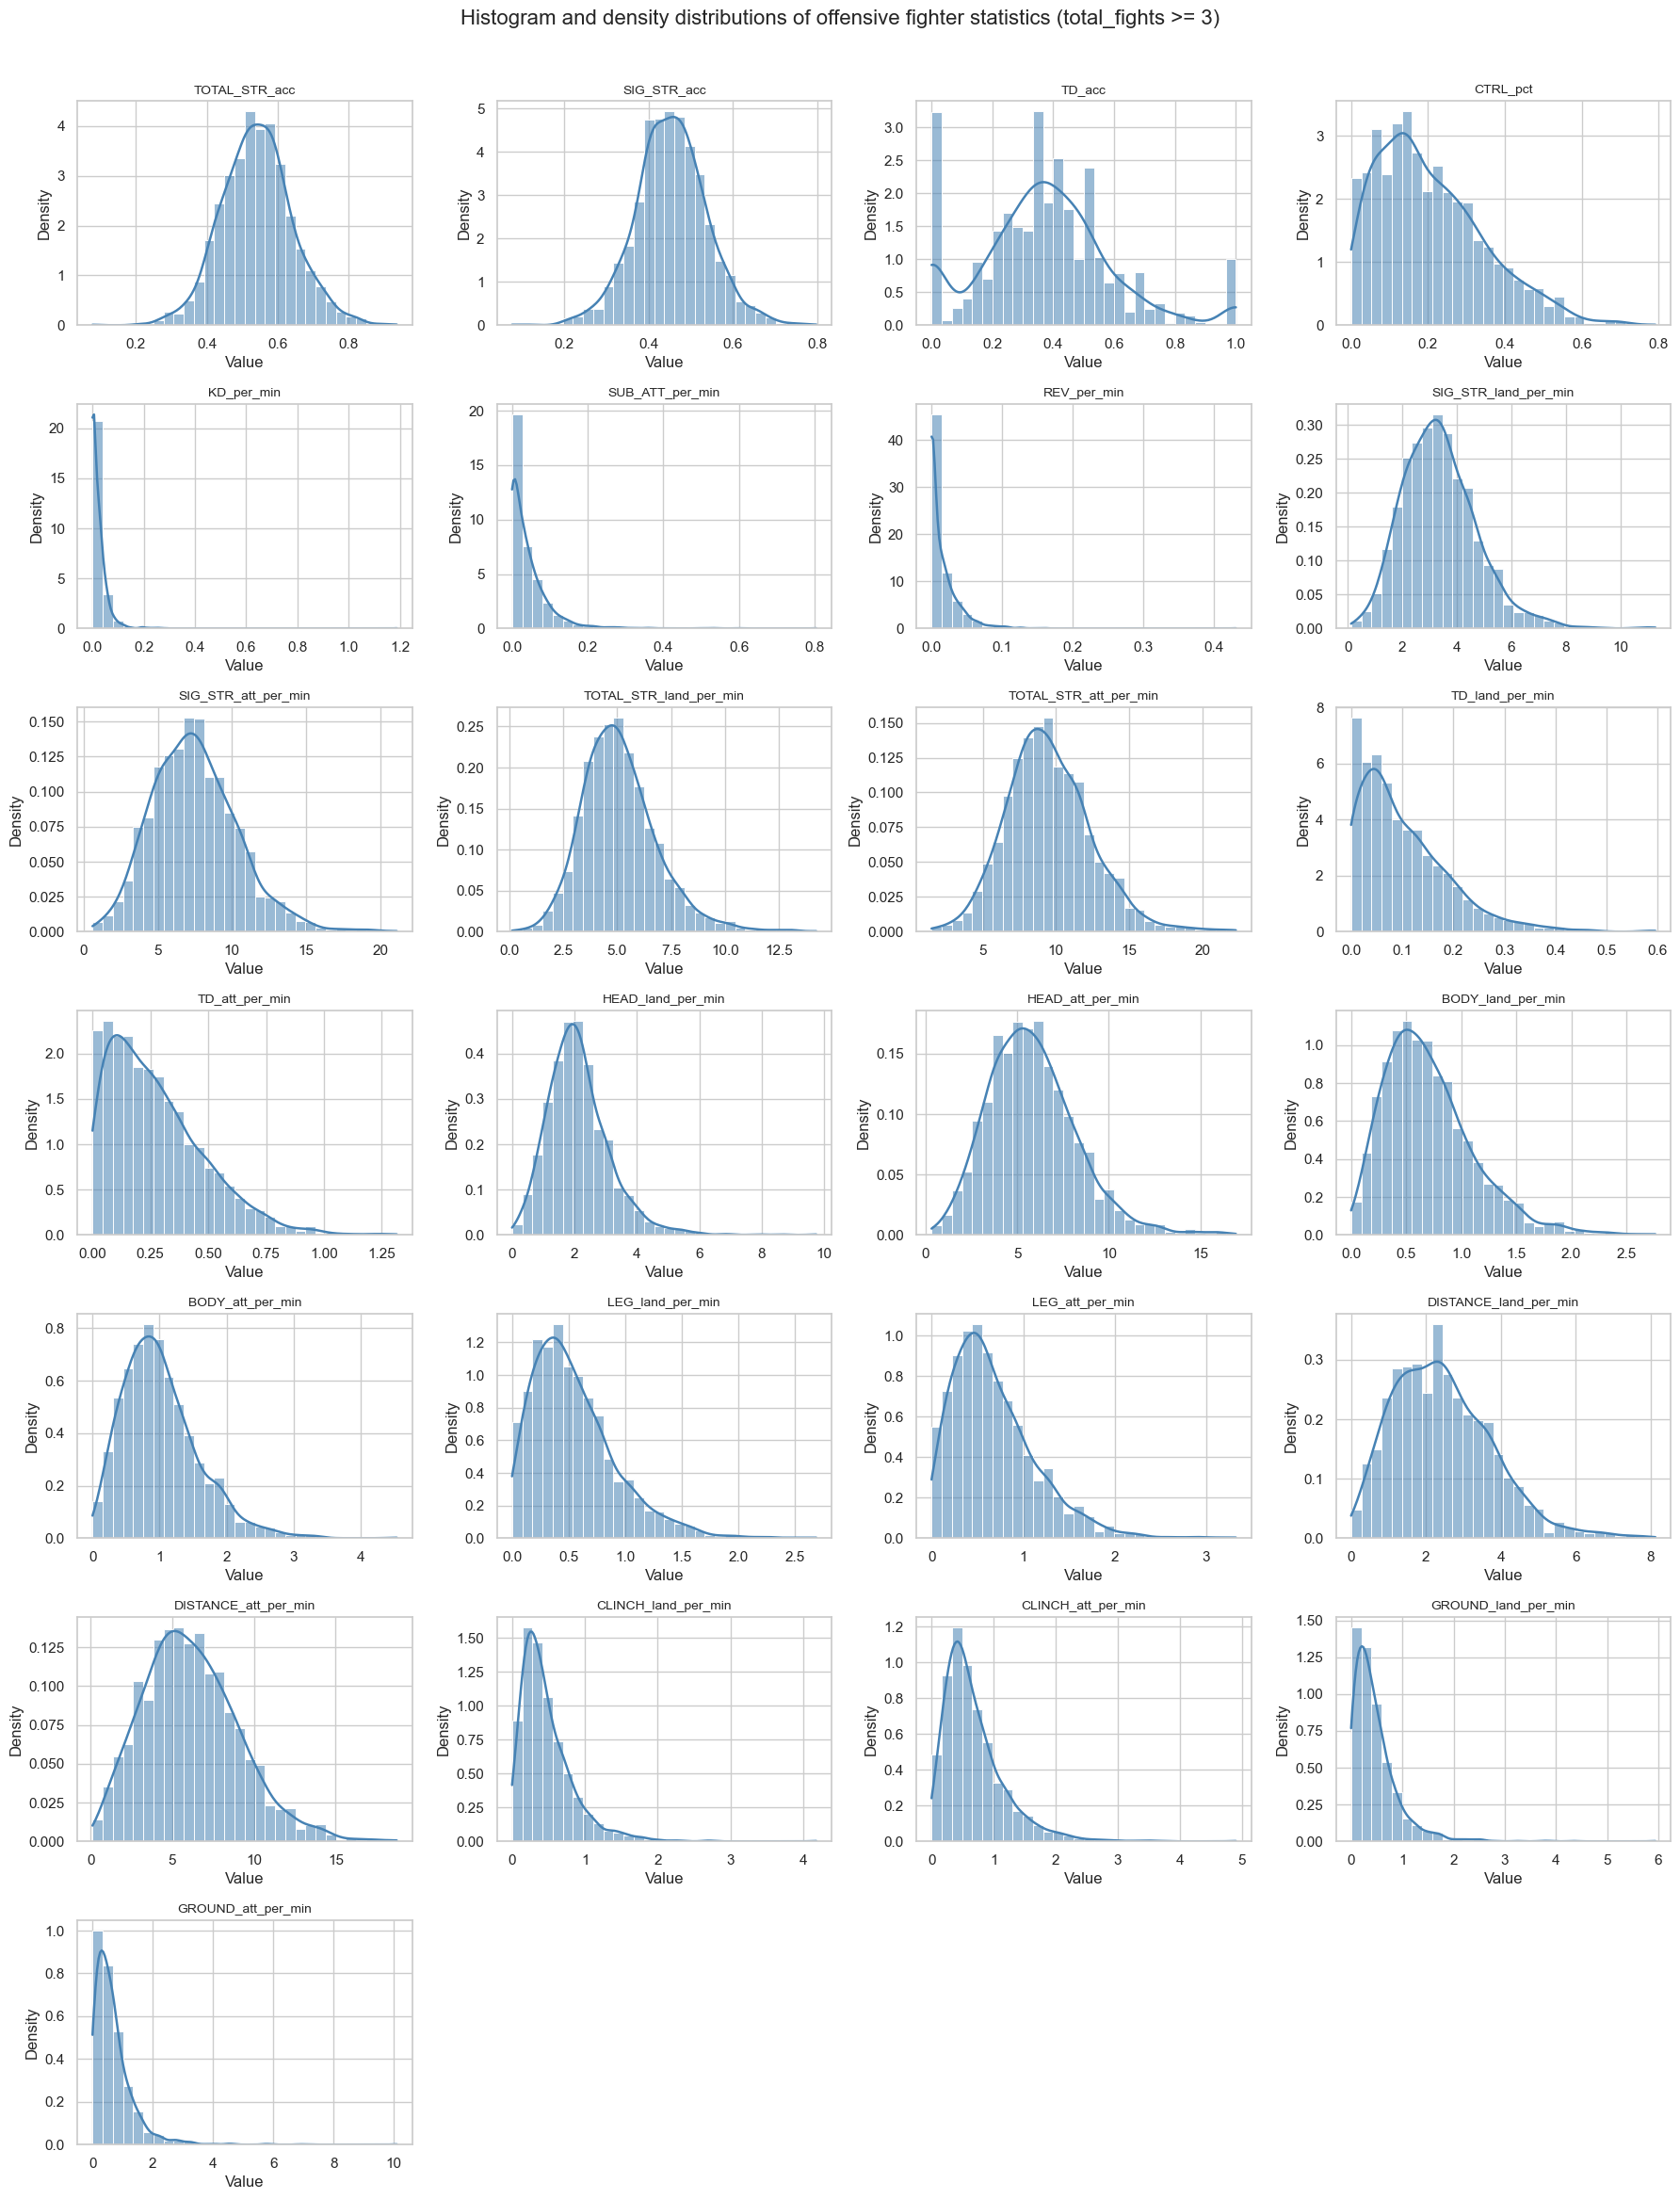

In [18]:
filtered_offensive_summary_columns = {
    "TOTAL_STR_acc",
    "SIG_STR_acc",
    "TD_acc",
    "CTRL_pct",
    "KD_per_min",
    "SUB_ATT_per_min",
    "REV_per_min",
}

filtered_offensive_columns = [
    column
    for column in filtered_continuous_stats.columns
    if (
        column in filtered_offensive_summary_columns
        or column.endswith(("_land_per_min", "_att_per_min"))
    )
    and "_opp_" not in column
    and "_absorbed_" not in column
]

n_columns = 4
n_rows = int(np.ceil(len(filtered_offensive_columns) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(18, 3.3 * n_rows))
axes = np.asarray(axes).ravel()

for ax, column in zip(axes, filtered_offensive_columns):
    values = filtered_continuous_stats[column].dropna()
    if values.nunique() > 1:
        sns.histplot(
            values,
            bins=30,
            stat="density",
            kde=True,
            color="steelblue",
            alpha=0.55,
            line_kws={"color": "navy", "linewidth": 1.8},
            ax=ax,
        )
    elif not values.empty:
        ax.axvline(values.iloc[0], linewidth=2)
    ax.set_title(column, fontsize=10)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

for ax in axes[len(filtered_offensive_columns):]:
    ax.remove()

fig.suptitle(
    "Histogram and density distributions of offensive fighter statistics (total_fights >= 3)",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()
plt.show()

In [19]:
filtered_pairwise_stats = filtered_continuous_stats[filtered_offensive_columns].dropna()
filtered_pairwise_stats = filtered_pairwise_stats.sample(
    n=min(600, len(filtered_pairwise_stats)), random_state=42
)

filtered_pair_grid = sns.pairplot(
    filtered_pairwise_stats,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"},
    diag_kws={"bins": 25},
)
filtered_pair_grid.figure.suptitle(
    "Pairwise scatterplot matrix of offensive fighter statistics (total_fights >= 3)",
    y=1.02,
)
plt.show()

KeyboardInterrupt: 

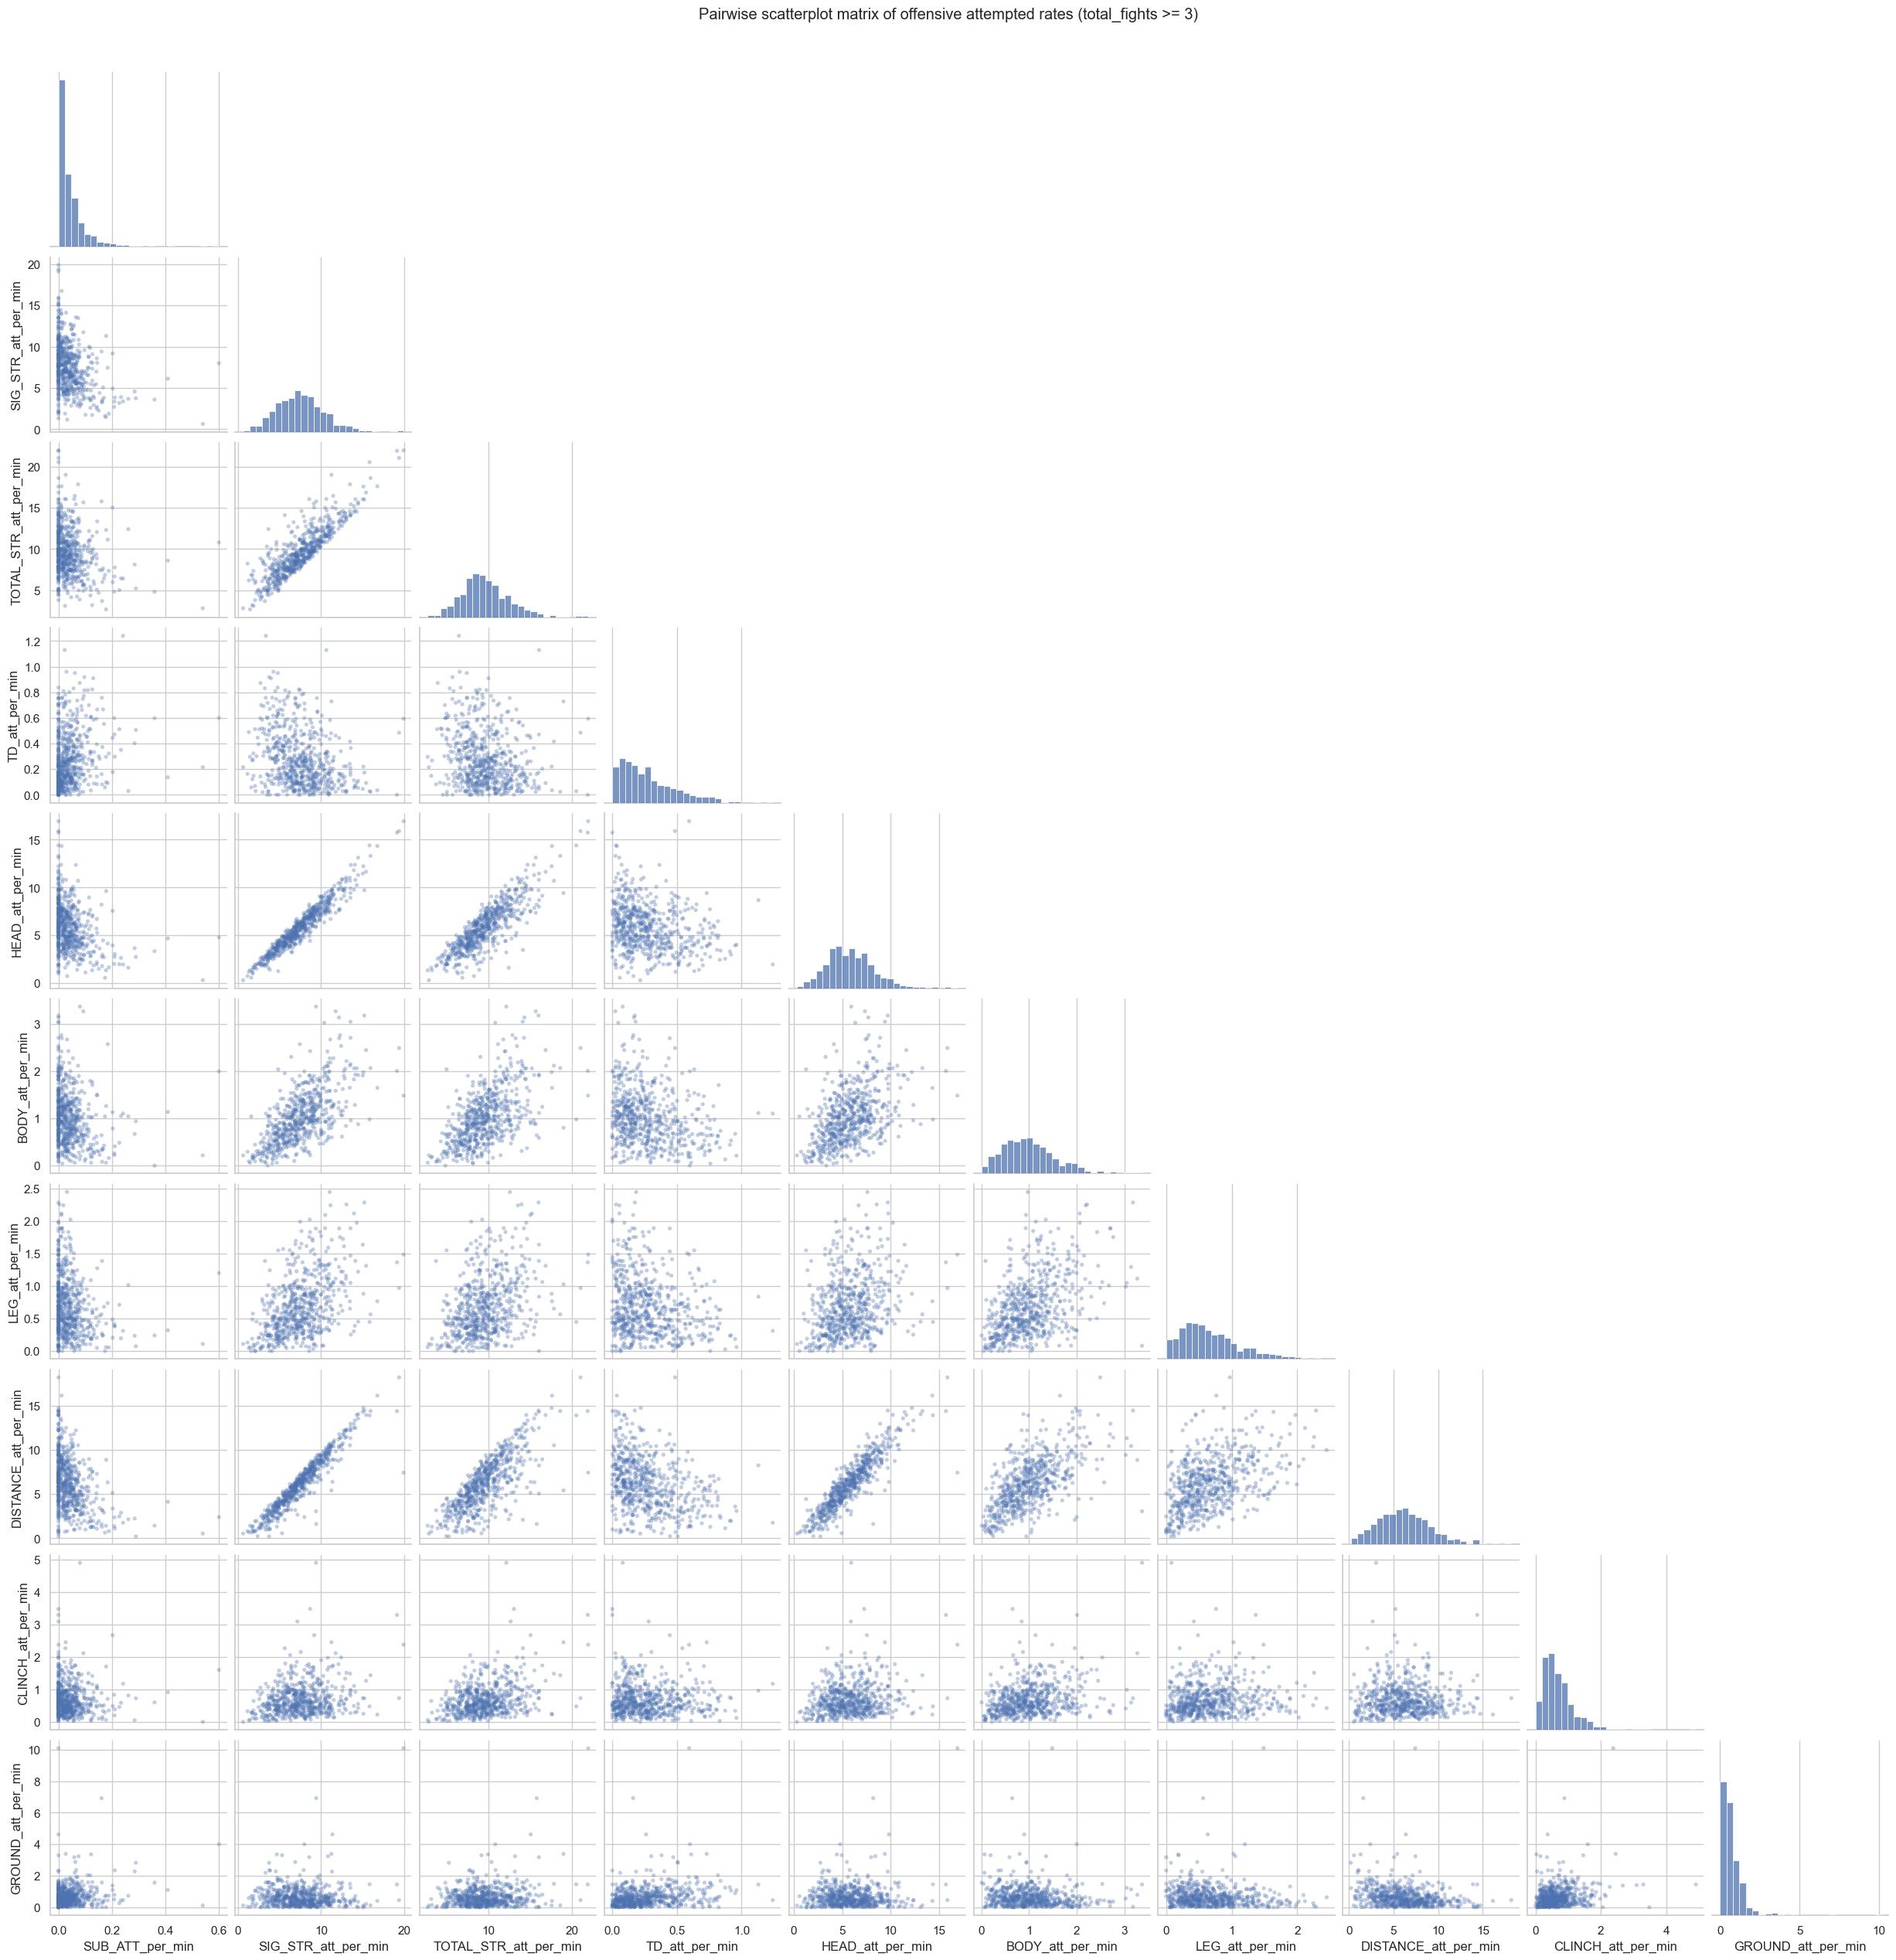

In [20]:
filtered_attempt_columns = [
    column
    for column in filtered_offensive_columns
    if column.lower().endswith("_att_per_min")
]
filtered_attempt_stats = filtered_continuous_stats[filtered_attempt_columns].dropna()
filtered_attempt_stats = filtered_attempt_stats.sample(
    n=min(600, len(filtered_attempt_stats)), random_state=42
)

filtered_attempt_grid = sns.pairplot(
    filtered_attempt_stats,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"},
    diag_kws={"bins": 25},
)
filtered_attempt_grid.figure.suptitle(
    "Pairwise scatterplot matrix of offensive attempted rates (total_fights >= 3)",
    y=1.02,
)
plt.show()